# Week 11 — Radiation Dosimetry

Ionizing-radiation imaging (X-ray, CT, fluoroscopy, nuclear) carries a **dose** cost. Dosimetry is the
science of **measuring** it. This notebook defines the units and simulates the key quantities.

| Quantity | Unit | Meaning |
|---|---|---|
| **Activity** | becquerel (Bq) = 1 decay/s | how many decays per second a source emits |
| **Absorbed dose** | gray (Gy) = 1 J/kg | energy deposited per unit mass of tissue |
| **Equivalent dose** | sievert (Sv) | absorbed dose weighted by radiation type ($w_R$) |
| **Effective dose** | sievert (Sv) | equivalent dose weighted by tissue sensitivity ($w_T$) — whole-body risk |
| **Entrance skin dose (ESD)** | mGy | dose at the skin where the beam enters (fluoroscopy burns) |

**Topics:** activity & decay (Bq), absorbed→equivalent→effective dose, the **entrance skin dose**
(inverse-square + backscatter), **cumulative fluoroscopy** dose and skin-injury thresholds, and
typical **effective doses** in context.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## 1. Activity — the becquerel

**Activity** is the decay rate $A=\lambda N$, where $\lambda=\ln 2/T_{1/2}$. One **becquerel** is one
decay per second; the older **curie** is $1\text{ Ci}=3.7\times10^{10}$ Bq. A typical injected dose is a
few **hundred MBq** (≈ 10 mCi), and it **decays** away over the scan.

injected: 10.0 mCi = 370 MBq
after 6 h: 185 MBq (5.0 mCi)


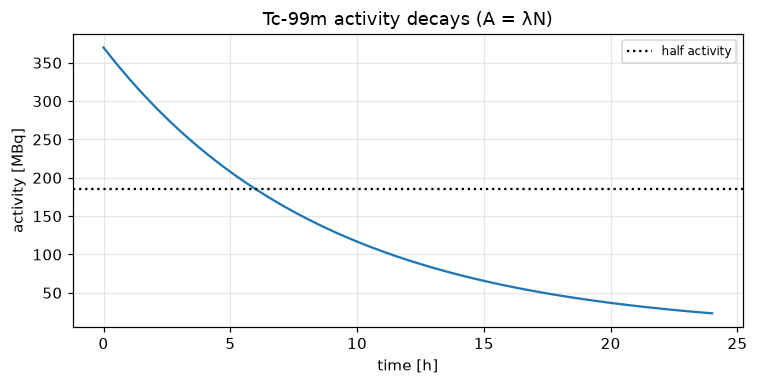

In [2]:
BQ_PER_MCI = 3.7e7                                   # 1 mCi = 37 MBq
A0_mCi = 10.0                                        # injected activity
A0 = A0_mCi * BQ_PER_MCI                             # in becquerels
half_life_h = 6.01                                   # Tc-99m
lam = np.log(2) / (half_life_h * 3600)              # decay constant [1/s]

t_h = np.linspace(0, 24, 300)
A = A0 * np.exp(-lam * t_h * 3600)
print(f"injected: {A0_mCi} mCi = {A0/1e6:.0f} MBq")
print(f"after 6 h: {A[np.argmin(abs(t_h-6))]/1e6:.0f} MBq ({A[np.argmin(abs(t_h-6))]/BQ_PER_MCI:.1f} mCi)")

plt.figure(figsize=(7, 3.6))
plt.plot(t_h, A / 1e6, color="tab:blue")
plt.axhline(A0 / 2e6, color="k", ls=":", label="half activity")
plt.xlabel("time [h]"); plt.ylabel("activity [MBq]"); plt.title("Tc-99m activity decays (A = λN)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 2. Absorbed → equivalent → effective dose

- **Absorbed dose** $D$ (gray) = energy deposited per kg.
- **Equivalent dose** $H=w_R\,D$ (sievert) weights by how damaging the radiation type is: $w_R=1$ for
  **X-ray/gamma/beta**, $5$–$20$ for neutrons, **20** for **alpha**. So for CT/X-ray, $\text{Sv}=\text{Gy}$.
- **Effective dose** $E=\sum_T w_T\,H_T$ (sievert) weights each organ's equivalent dose by its
  sensitivity $w_T$ (ICRP) and sums — a single whole-body number tied to **stochastic (cancer) risk**.

In [3]:
w_R = {"X-ray / gamma": 1, "beta": 1, "proton": 2, "neutron": 10, "alpha": 20}
print("radiation weighting factors w_R:")
for k, v in w_R.items():
    print(f"  {k:16s} {v}")

# Effective dose from a CT abdomen: organ absorbed doses (mGy) x tissue weights w_T (ICRP 103)
organ_D = {"stomach": 12, "colon": 14, "liver": 11, "gonads": 8, "red marrow": 6, "skin": 4}
w_T =     {"stomach": 0.12, "colon": 0.12, "liver": 0.04, "gonads": 0.08, "red marrow": 0.12, "skin": 0.01}
E = sum(w_T[o] * organ_D[o] for o in organ_D)      # x-ray -> w_R=1, so H=D
print(f"\neffective dose (this partial model) = {E:.2f} mSv")

radiation weighting factors w_R:
  X-ray / gamma    1
  beta             1
  proton           2
  neutron          10
  alpha            20

effective dose (this partial model) = 4.96 mSv


## 3. Entrance skin dose: inverse-square + backscatter

In fluoroscopy the **entrance skin dose (ESD)** is what can burn the patient. It scales with tube
output (roughly $\propto \text{mAs}\cdot\text{kVp}^2$), falls with distance by the **inverse-square
law**, and is raised ~30–50% by a **backscatter factor (BSF)**:
$$\text{ESD} = Y(\text{kVp})\cdot \text{mAs}\cdot\left(\frac{d_\text{ref}}{d_\text{skin}}\right)^2\cdot \text{BSF}.$$
Keeping the skin **farther** from the source is one of the strongest dose-reduction levers.

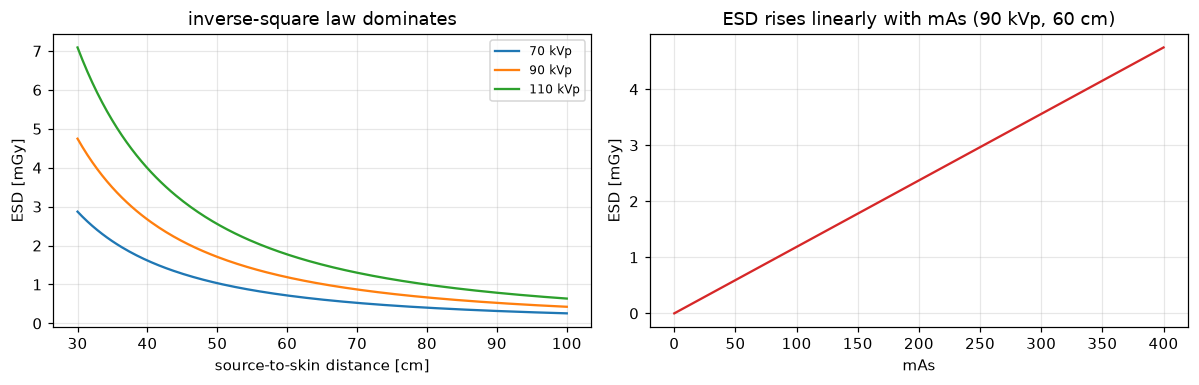

In [4]:
def esd_mGy(kVp, mAs, d_skin_cm, d_ref_cm=100.0, bsf=1.35):
    Y = 0.0025 * (kVp / 80.0) ** 2            # output [mGy/mAs] at d_ref, normalized ~80 kVp
    return Y * mAs * (d_ref_cm / d_skin_cm) ** 2 * bsf

d = np.linspace(30, 100, 200)                  # source-to-skin distance [cm]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for kVp in [70, 90, 110]:
    ax[0].plot(d, esd_mGy(kVp, mAs=100, d_skin_cm=d), label=f"{kVp} kVp")
ax[0].set_xlabel("source-to-skin distance [cm]"); ax[0].set_ylabel("ESD [mGy]")
ax[0].set_title("inverse-square law dominates"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

mAs = np.linspace(0, 400, 200)
ax[1].plot(mAs, esd_mGy(90, mAs, d_skin_cm=60), color="tab:red")
ax[1].set_xlabel("mAs"); ax[1].set_ylabel("ESD [mGy]")
ax[1].set_title("ESD rises linearly with mAs (90 kVp, 60 cm)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Cumulative fluoroscopy dose and skin-injury thresholds

Long interventional procedures (e.g. **VT ablation**) accumulate skin dose = **dose rate × time**.
Deterministic skin effects have thresholds: **~2 Gy** transient erythema, **~3 Gy** temporary
epilation, **~7 Gy** permanent epilation, **>15 Gy** dermal necrosis (radiation burn). This is why
pre-op image fusion that cuts fluoroscopy time matters.

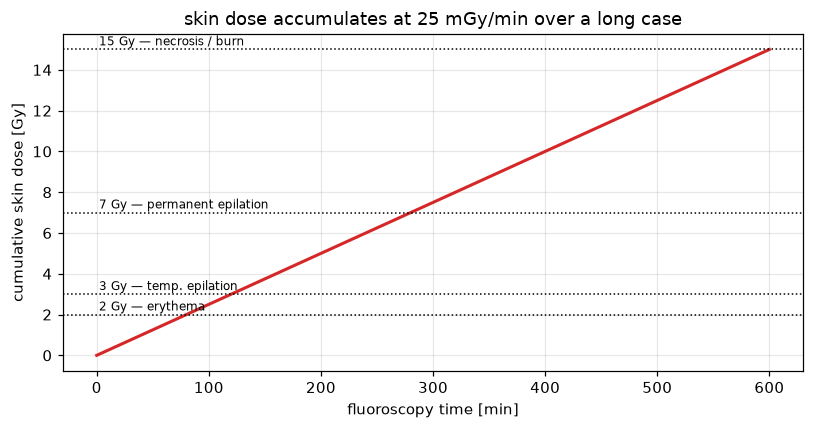

after 10 h at 25 mGy/min: 15.0 Gy (reaches the dermal-necrosis / burn threshold)


In [5]:
dose_rate = 25.0                                   # mGy/min typical skin dose rate
minutes = np.linspace(0, 600, 300)   # up to a 10-hour interventional case
cum_Gy = dose_rate * minutes / 1000.0              # cumulative skin dose [Gy]

plt.figure(figsize=(7.5, 4))
plt.plot(minutes, cum_Gy, color="tab:red", lw=2)
for thr, label in [(2, "erythema"), (3, "temp. epilation"), (7, "permanent epilation"), (15, "necrosis / burn")]:
    plt.axhline(thr, color="k", ls=":", lw=1)
    plt.text(2, thr + 0.2, f"{thr} Gy — {label}", fontsize=8)
plt.xlabel("fluoroscopy time [min]"); plt.ylabel("cumulative skin dose [Gy]")
plt.title(f"skin dose accumulates at {dose_rate:.0f} mGy/min over a long case")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"after 10 h at {dose_rate:.0f} mGy/min: {dose_rate*600/1000:.1f} Gy (reaches the dermal-necrosis / burn threshold)")

## 5. Effective dose in context

**Effective dose** (mSv) lets us compare very different exposures on one risk scale, against the
~**3 mSv/year** natural background. A chest X-ray is trivial; a multiphase abdominal CT is ~1000×
larger — the dose/benefit trade-off behind *as-low-as-reasonably-achievable* (**ALARA**).

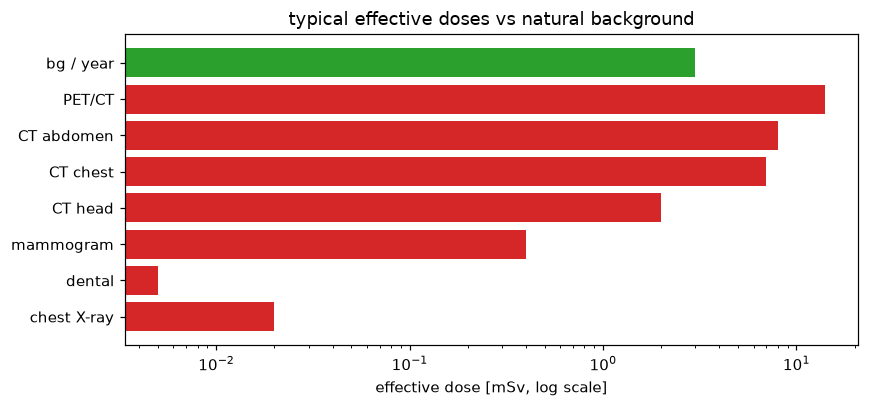

In [6]:
exams = {
    "chest X-ray": 0.02, "dental": 0.005, "mammogram": 0.4, "CT head": 2.0,
    "CT chest": 7.0, "CT abdomen": 8.0, "PET/CT": 14.0, "bg / year": 3.0,
}
names = list(exams); vals = list(exams.values())
colors = ["tab:green" if n == "bg / year" else "tab:red" for n in names]

plt.figure(figsize=(8, 3.8))
plt.barh(names, vals, color=colors)
plt.xscale("log"); plt.xlabel("effective dose [mSv, log scale]")
plt.title("typical effective doses vs natural background")
plt.tight_layout(); plt.show()

## Takeaways

- **Becquerel** = decays/s (activity $A=\lambda N$); injected activity **decays** during the study.
- **Gray** = absorbed energy per mass; **Sievert** weights it for harm — $H=w_R D$ (radiation type,
  $w_R=1$ for X-ray/gamma, 20 for alpha) and $E=\sum w_T H_T$ (tissue sensitivity → whole-body risk).
- **Entrance skin dose** follows the **inverse-square law** and a **backscatter factor**; distance and
  mAs/kVp are the control knobs.
- **Cumulative fluoroscopy** dose can cross **deterministic** skin-injury thresholds (erythema ~2 Gy →
  burn >15 Gy) — the reason to minimize beam-on time.
- **Effective dose** compares exams on one scale against ~3 mSv/yr background, guiding **ALARA**.
- Tools like entrance-skin-dose software (e.g. for fluoroscopy) turn these formulae into real-time maps.